#### Importation des modules et du dataset d'entrainement

In [ ]:
# Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from optbinning import MulticlassOptimalBinning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from scipy.stats import kruskal

In [3]:
# Importation du dataset d'entrainement
df = pd.read_csv("../data/Train.csv")

Description des variables

| Variable | Description |
|---|---|
| `ID` | Identifiant unique du client |
| `Gender` | Genre du client |
| `Ever_Married` | État civil du client |
| `Age` | Âge du client |
| `Graduated` | Indique si le client est diplômé |
| `Profession` | Profession du client |
| `Work_Experience` | Expérience professionnelle (en années) |
| `Spending_Score` | Score de dépenses du client |
| `Family_Size` | Nombre de membres dans la famille (client inclus) |
| `Var_1` | Catégorie anonymisée du client |
| `Segmentation` | Segment cible du client *(variable à prédire)* |

In [4]:
print(df.info())
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB
None
(8068, 11)


In [5]:
# Split Train Test

X = df.drop('Segmentation', axis=1)
y = df['Segmentation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                      stratify=y, random_state=42)

print(f"Train : {X_train.shape[0]} lignes")
print(f"Test  : {X_test.shape[0]} lignes")

Train : 6454 lignes
Test  : 1614 lignes


In [28]:
num_vars = ['Age', 'Work_Experience', 'Family_Size']
cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']
# target = ['Segmentation']

##### Analyse Univariée

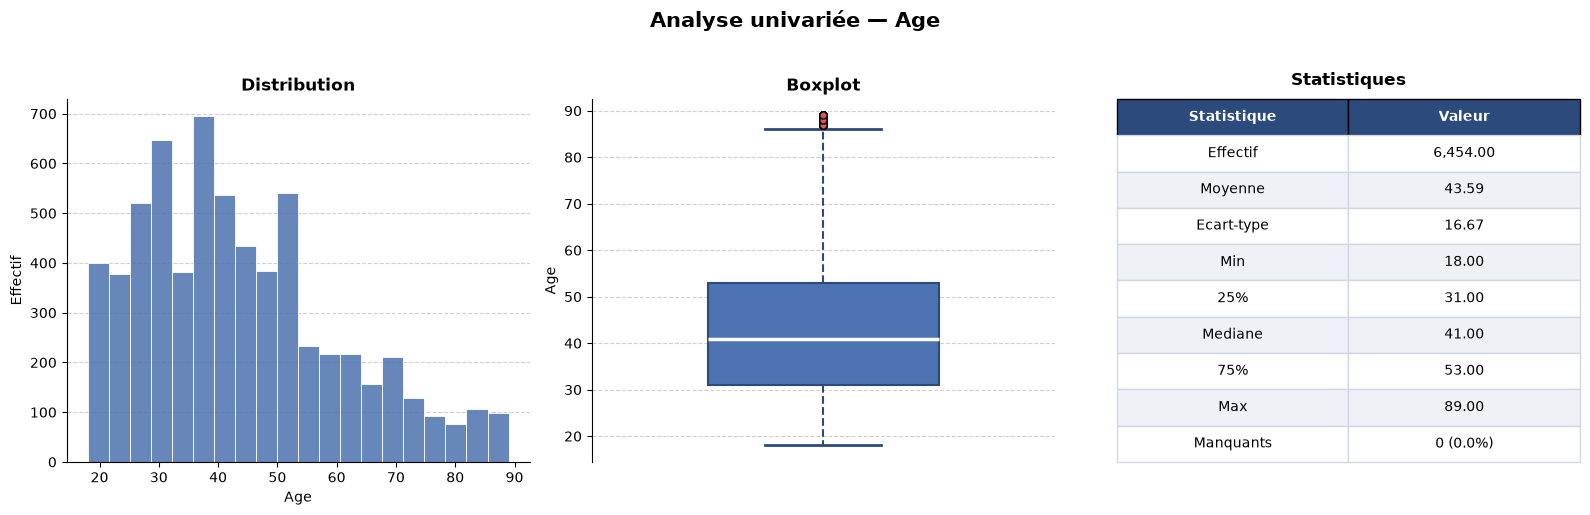

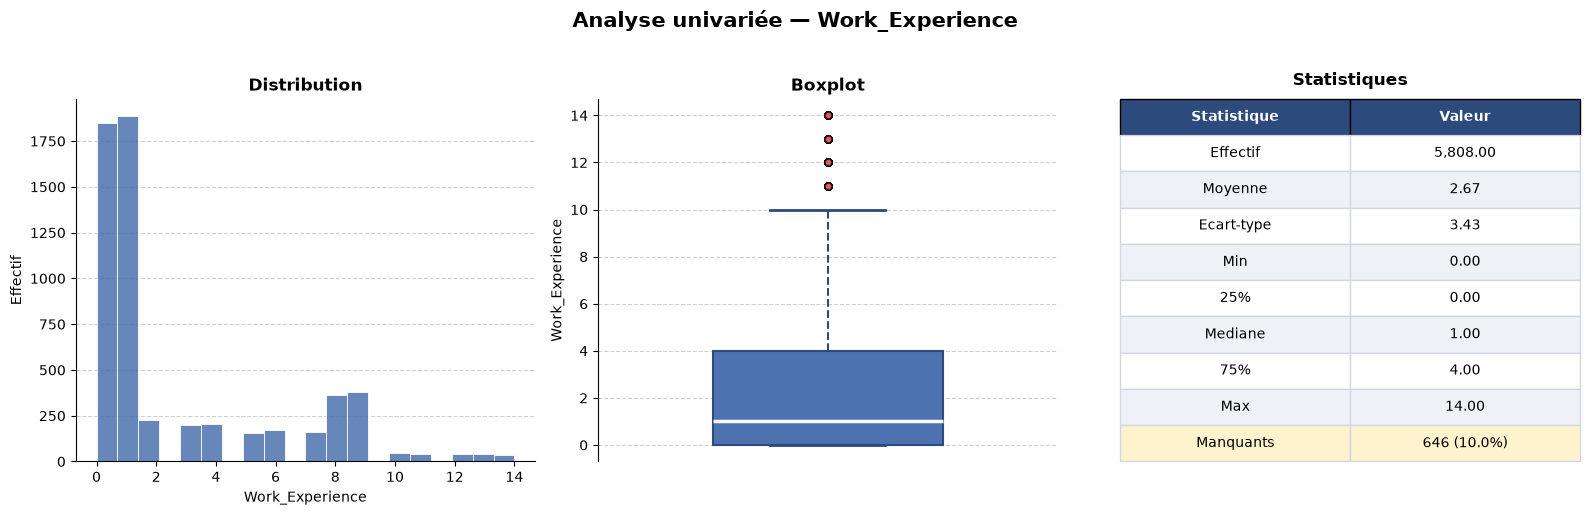

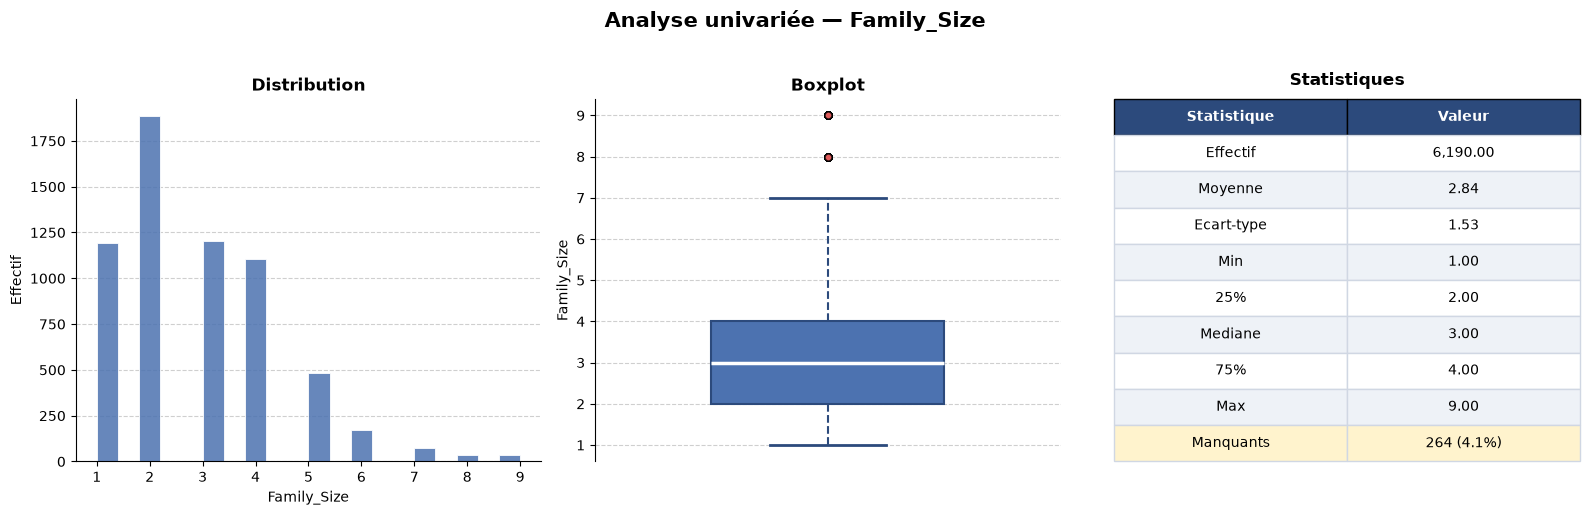

In [14]:
## Analyse Univariée des variables quantitatives

warnings.filterwarnings('ignore')

for col in num_vars:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    color_main = '#4C72B0'
    color_dark  = '#2c4a7c'

    # --- Histogramme ---
    ax = axes[0]
    ax.hist(X_train[col].dropna(), bins=20, color=color_main,
            edgecolor='white', linewidth=0.7, alpha=0.85)

    ax.set_title('Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Effectif', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

    # --- Boxplot ---
    ax = axes[1]
    bp = ax.boxplot(X_train[col].dropna(), patch_artist=True, orientation='vertical',
                    widths=0.5,
                    boxprops=dict(facecolor=color_main, color=color_dark, linewidth=1.5),
                    medianprops=dict(color='white', linewidth=2.5),
                    whiskerprops=dict(color=color_dark, linewidth=1.5, linestyle='--'),
                    capprops=dict(color=color_dark, linewidth=2),
                    flierprops=dict(marker='o', color=color_dark,
                                   markerfacecolor='#e05c5c', markersize=5, alpha=0.7))

    ax.set_title('Boxplot', fontsize=12, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)

    # --- Stats descriptives ---
    ax = axes[2]
    ax.axis('off')

    stats = X_train[col].describe().round(2)
    missing = X_train[col].isnull().sum()
    missing_pct = X_train[col].isnull().mean() * 100

    labels = {
        'count': 'Effectif', 'mean': 'Moyenne', 'std': 'Ecart-type',
        'min': 'Min', '25%': '25%', '50%': 'Mediane',
        '75%': '75%', 'max': 'Max'
    }

    table_data = [[labels.get(k, k), f"{v:,.2f}"] for k, v in stats.items()]
    table_data.append(['Manquants', f"{missing} ({missing_pct:.1f}%)"])

    table = ax.table(
        cellText=table_data,
        colLabels=['Statistique', 'Valeur'],
        loc='center', cellLoc='center',
        bbox=[0, 0, 1, 1]
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)

    for j in range(2):
        table[0, j].set_facecolor(color_dark)
        table[0, j].set_text_props(color='white', fontweight='bold')

    for i in range(1, len(table_data) + 1):
        for j in range(2):
            table[i, j].set_facecolor('#eef2f7' if i % 2 == 0 else 'white')
            table[i, j].set_edgecolor('#d0d7e3')

    if missing > 0:
        for j in range(2):
            table[len(table_data), j].set_facecolor('#fff3cd')

    ax.set_title('Statistiques', fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.show()

In [7]:
## Discrétisation des variables quantitatives
binners = {}

for col in num_vars:

    optb = MulticlassOptimalBinning(name=col)  # ← pas de dtype

    mask = X_train[col].notna() & y_train.notna()
    optb.fit(X_train.loc[mask, col].values, y_train[mask].values)

    print(f"=== {col} ===")
    print(optb.binning_table.build())

    X_train[f'{col}_bin'] = optb.transform(X_train[col].values, metric="bins")
    binners[col] = optb

# Appliquer sur X_test
for col in num_vars:
    X_test[f'{col}_bin'] = binners[col].transform(X_test[col].values, metric="bins")


=== Age ===
                   Bin  Count  Count (%)  Event_A  Event_B  Event_C  Event_D  \
0        (-inf, 24.00)    607   0.094050       20       19       29      539   
1       [24.00, 28.50)    692   0.107220      170       94       94      334   
2       [28.50, 34.00)    831   0.128757      230      113      117      371   
3       [34.00, 44.00)   1620   0.251007      557      456      333      274   
4         [44.00, inf)   2704   0.418965      601      804     1003      296   
5              Special      0   0.000000        0        0        0        0   
6              Missing      0   0.000000        0        0        0        0   
Totals                   6454   1.000000     1578     1486     1576     1814   

        Event_rate_A  Event_rate_B  Event_rate_C  Event_rate_D  
0           0.032949      0.031301      0.047776      0.887974  
1           0.245665      0.135838      0.135838      0.482659  
2           0.276775      0.135981      0.140794      0.446450  
3      

In [ ]:
# # 1. Imputer Work_Experience
# train['Work_Experience'].fillna(train['Work_Experience'].median(), inplace=True)

# # 2. Imputer Family_Size
# train['Family_Size'].fillna(train['Family_Size'].median(), inplace=True)

# # 3. Log-transform Work_Experience
# import numpy as np
# train['Work_Experience_log'] = np.log1p(train['Work_Experience'])


# (penser aussi à la standardiser les var_num au cas où je fais la reg log, la log-transformation c'est aussi pour la reg log)

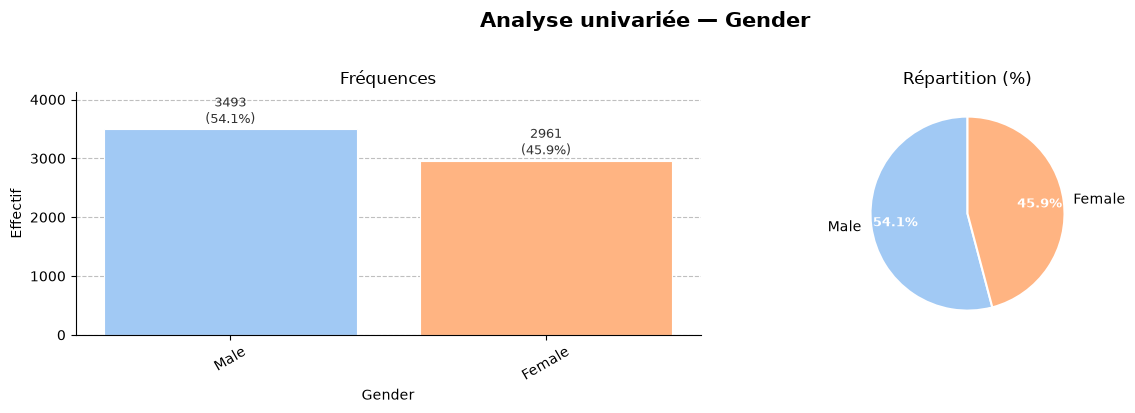

→ Modalités : 2
→ Valeurs manquantes : 0 (0.0%)


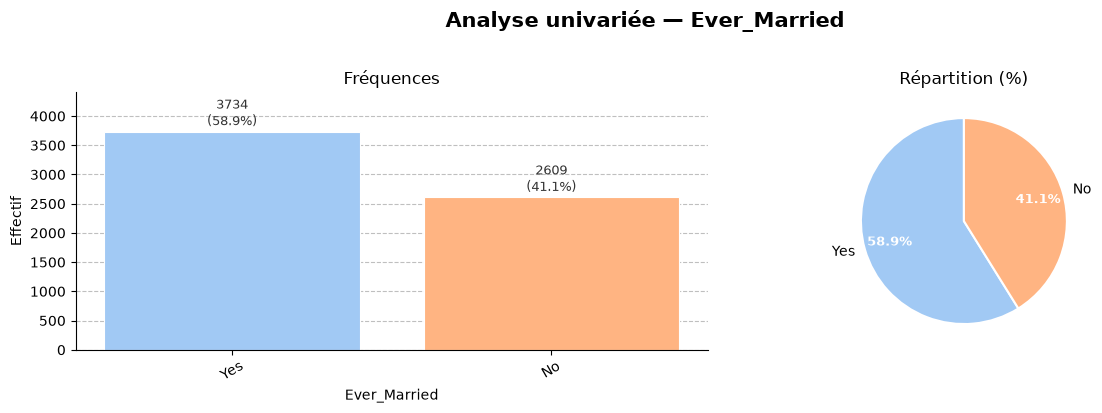

→ Modalités : 2
→ Valeurs manquantes : 111 (1.7%)


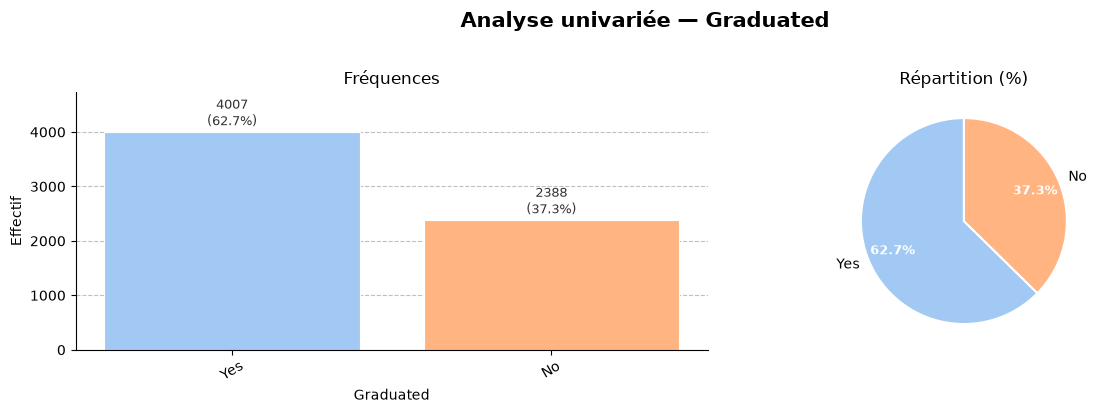

→ Modalités : 2
→ Valeurs manquantes : 59 (0.9%)


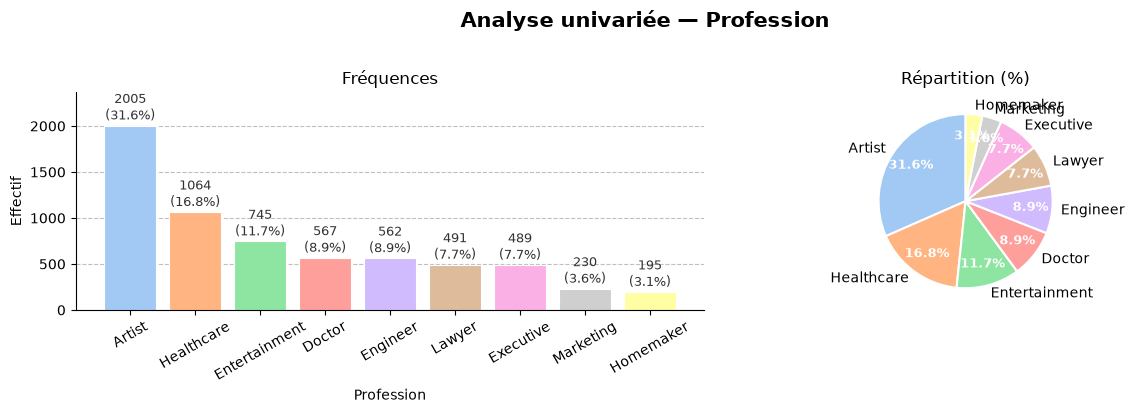

→ Modalités : 9
→ Valeurs manquantes : 106 (1.6%)


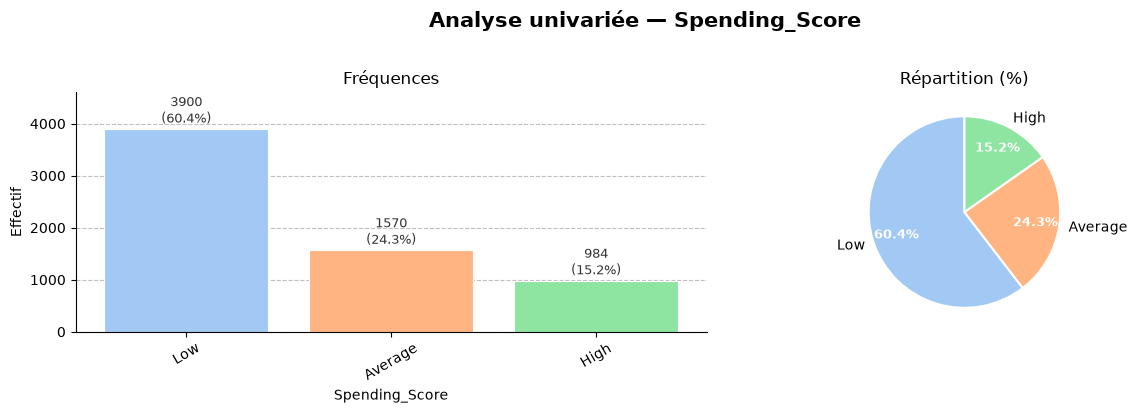

→ Modalités : 3
→ Valeurs manquantes : 0 (0.0%)


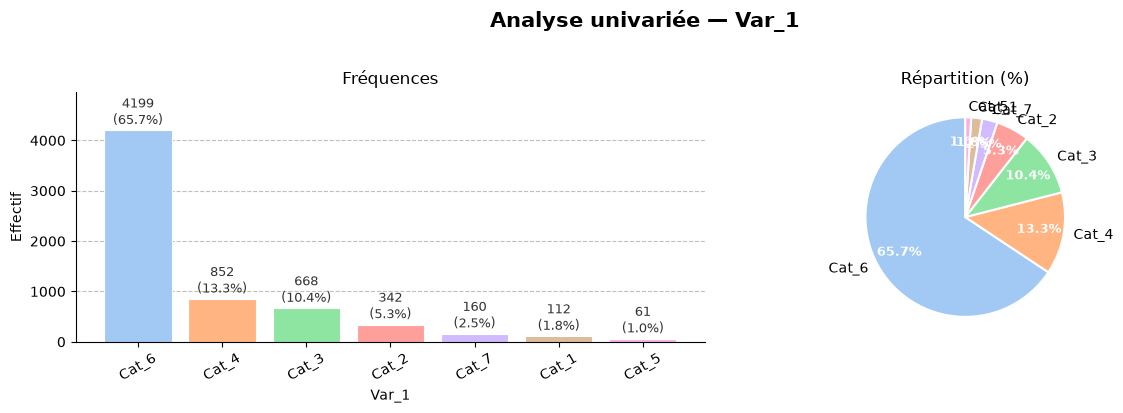

→ Modalités : 7
→ Valeurs manquantes : 60 (0.9%)


In [34]:
## Analyse Univariée des variables catégorielles

for col in cat_vars:
    counts = X_train[col].value_counts()
    pcts = X_train[col].value_counts(normalize=True) * 100
    n = len(counts)

    # Palette dynamique selon le nombre de modalités
    palette = sns.color_palette("pastel", n)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    # --- Bar chart ---
    bars = axes[0].bar(counts.index.astype(str), counts.values,
                       color=palette, edgecolor='white', linewidth=0.8)

    # Annotations au-dessus des barres
    for bar, val, pct in zip(bars, counts.values, pcts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + max(counts.values) * 0.01,
                     f'{val}\n({pct:.1f}%)',
                     ha='center', va='bottom', fontsize=9, color='#333333')

    axes[0].set_title('Fréquences', fontsize=12)
    axes[0].set_xlabel(col, fontsize=10)
    axes[0].set_ylabel('Effectif', fontsize=10)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].set_ylim(0, max(counts.values) * 1.18)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5, color='gray')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # --- Pie chart ---
    wedges, texts, autotexts = axes[1].pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=palette,
        wedgeprops=dict(edgecolor='white', linewidth=1.5),
        pctdistance=0.75
    )
    for at in autotexts:
        at.set_fontsize(9)
        at.set_color('white')
        at.set_fontweight('bold')
    axes[1].set_title('Répartition (%)', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Résumé texte
    print(f"→ Modalités : {X_train[col].nunique()}")
    print(f"→ Valeurs manquantes : {X_train[col].isnull().sum()} ({X_train[col].isnull().mean()*100:.1f}%)")
    # print(pd.DataFrame({'Effectif': counts, 'Pourcentage (%)': pcts.round(1)}), '\n')

In [12]:
X_train['Profession_group'].unique()

<StringArray>
['Creative', 'Healthcare', 'Engineer', 'Lawyer', 'Other', 'Executive', nan]
Length: 7, dtype: str

In [ ]:
# Regroupement de la variable Profession
profession_map = {
    'Artist':         'Creative',
    'Entertainment':  'Creative',
    'Healthcare':     'Healthcare',
    'Doctor':         'Healthcare',
    'Engineer':       'Engineer',
    'Lawyer':         'Lawyer',
    'Executive':      'Executive',
    'Marketing':      'Other',
    'Homemaker':      'Other'
}

X_train['Profession_group'] = X_train['Profession'].map(profession_map)
X_test['Profession_group'] = X_test['Profession'].map(profession_map)

## Regroupement Var_1
Var_1_map = {
    'Cat_6':  'Cat_6',
    'Cat_4':  'Cat_4',
    'Cat_3':   'Cat_3',
    'Cat_2':   'Other',
    'Cat_7':   'Other',
    'Cat_1':   'Other',
    'Cat_5':   'Other',
}

X_train['Var_1_group'] = X_train['Var_1'].map(Var_1_map)
X_test['Var_1_group'] = X_test['Var_1'].map(Var_1_map)

Profession_group
Creative      2750
Healthcare    1631
Engineer       562
Lawyer         491
Executive      489
Other          425
Name: count, dtype: int64

Valeurs manquantes : 106


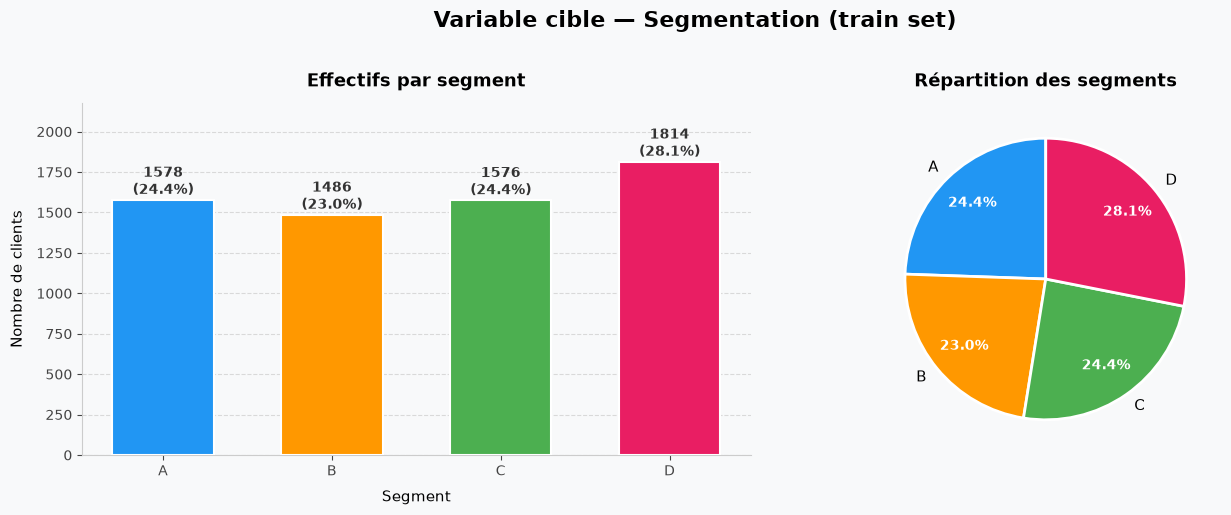

In [25]:
# Target

colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']
counts = y_train.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Variable cible — Segmentation (train set)', fontsize=16, fontweight='bold', y=1.02)
fig.patch.set_facecolor('#F8F9FA')

# ── Bar chart ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#F8F9FA')

bars = ax.bar(counts.index.astype(str), counts.values,
              color=colors, edgecolor='white', linewidth=1.5,
              width=0.6, zorder=3)

# Annotations valeurs + pourcentages
for bar, val in zip(bars, counts.values):
    pct = val / len(y_train) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            f'{val}\n({pct:.1f}%)', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='#333333')

ax.set_title('Effectifs par segment', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Segment', fontsize=11, labelpad=8)
ax.set_ylabel('Nombre de clients', fontsize=11, labelpad=8)
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.grid(True, linestyle='--', alpha=0.7, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(axis='both', labelsize=10, colors='#444444')

# ── Pie chart ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')

wedges, texts, autotexts = ax2.pie(
    counts.values,
    labels=counts.index.astype(str),
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11)
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax2.set_title('Répartition des segments', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

- Pas de déséquilibre

##### Analyse Bivariée

In [26]:
target = 'Segmentation'
colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']

df_train = X_train.copy()
df_train[target] = y_train.values

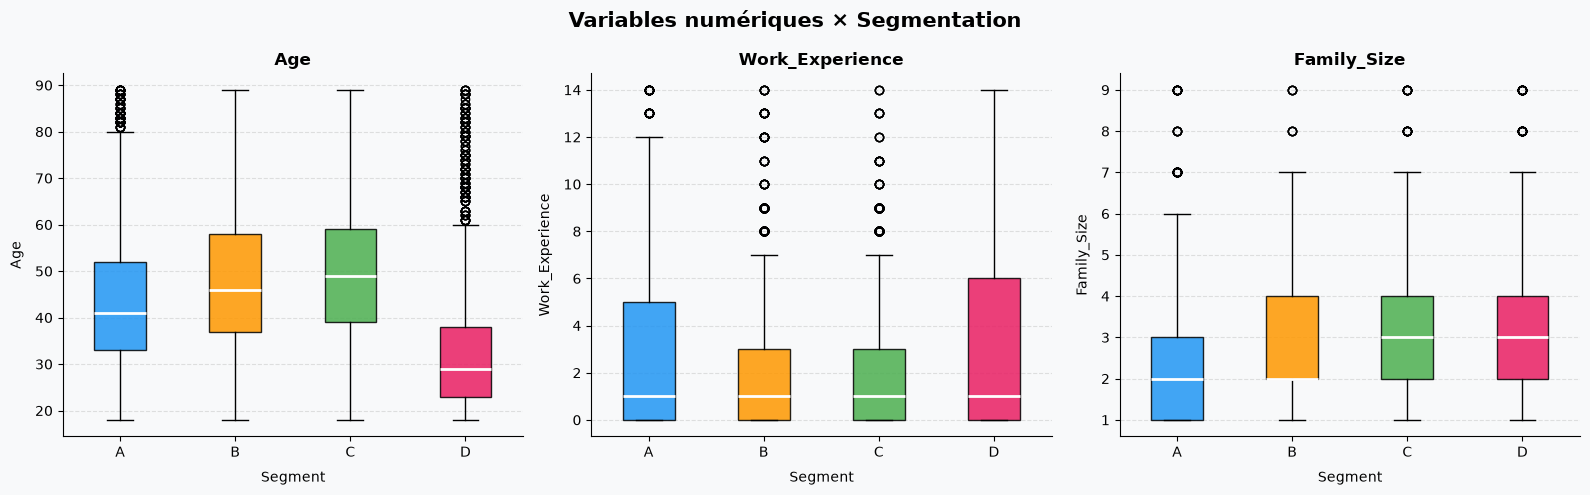

In [29]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Variables numériques × Segmentation', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    data = [df_train[df_train[target] == seg][col].dropna()
            for seg in sorted(df_train[target].unique())]

    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color='white', linewidth=2))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xticklabels(sorted(df_train[target].unique()), fontsize=10)
    ax.set_xlabel('Segment', labelpad=8)
    ax.set_ylabel(col, labelpad=8)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

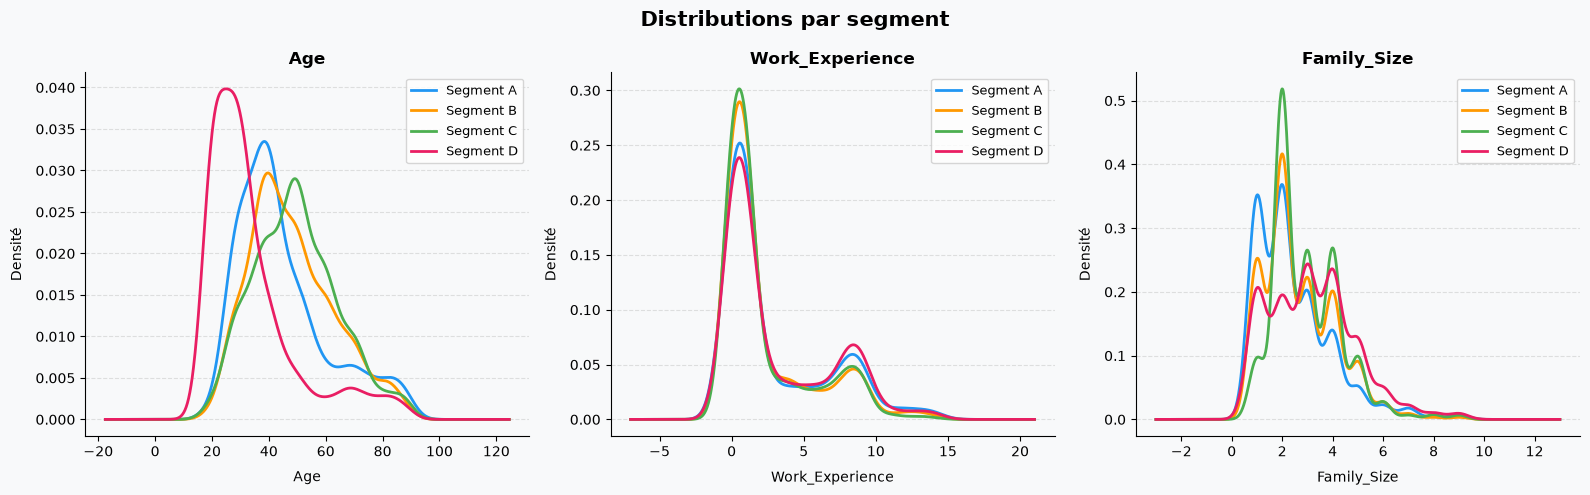

In [30]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Distributions par segment', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    for seg, color in zip(sorted(df_train[target].unique()), colors):
        subset = df_train[df_train[target] == seg][col].dropna()
        subset.plot.kde(ax=ax, label=f'Segment {seg}', color=color, linewidth=2)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col, labelpad=8)
    ax.set_ylabel('Densité', labelpad=8)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [38]:

for col in num_vars:
    groups = [df_train[df_train['Segmentation'] == seg][col].dropna()
          for seg in sorted(df_train['Segmentation'].unique())]

    stat, p = kruskal(*groups)
    print(f"H_{col}={stat:.3f}, p_{col}={p:.4f}")

H_Age=1344.868, p_Age=0.0000
H_Work_Experience=38.870, p_Work_Experience=0.0000
H_Family_Size=251.002, p_Family_Size=0.0000


D'après le test de kruskal-Wallis, l'Age, l'expérience de travail et la taille de la famille ont un impact significatif sur la segmentation client